Resources for analysis:

* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_analysis/DE_Analysis_mm_with_quizzes_fixed
* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_reduction/03-counts_mm
* https://github.com/ben-laufer/RNA-seq/blob/main/04-limma-voom.R
* https://raw.githubusercontent.com/ucdavis-bioinformatics-training/2020-mRNA_Seq_Workshop/master/data_analysis/enrichment_mm.Rmd

I switched between batch 1 and 2 data by changing every instance of "batch1" to "batch2" and vice versa.

# Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

# Load Libraries

In [3]:
library(edgeR)
library(rtracklayer)
library(gplots)
library(RColorBrewer)
library(dplyr)
library(ggplot2)

# Load Metadata

In [5]:
# Read in metadata
metadata <- read.csv("metadata.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$Gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ HD:'data.frame':	12 obs. of  9 variables:
  ..$ Gene       : chr [1:12] "HD" "HD" "HD" "HD" ...
  ..$ Sample_ID  : chr [1:12] "AS1" "AS2" "AS3" "AS4" ...
  ..$ Cell_Type  : chr [1:12] "CtO" "CtO" "CtO" "CtO" ...
  ..$ Genotype   : chr [1:12] "MUT" "MUT" "MUT" "MUT" ...
  ..$ Treatment  : chr [1:12] "Guide6" "Guide6" "Guide6" "NonEffector" ...
  ..$ Group      : chr [1:12] "MUT_Guide6" "MUT_Guide6" "MUT_Guide6" "MUT_NonEffector" ...
  ..$ Sample_Name: chr [1:12] "MUT_Guide6_1" "MUT_Guide6_2" "MUT_Guide6_3" "MUT_NonEffector_1" ...
  ..$ Replicate  : int [1:12] 1 2 3 1 2 3 1 2 3 1 ...
  ..$ Batch      : int [1:12] 0 0 0 1 1 1 1 1 1 1 ...


In [6]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$Group))
}


=== Group counts for HD ===

     MUT_Guide6 MUT_NonEffector          MUT_NT           WT_NT 
              3               3               3               3 


# Load Counts

In [7]:
# Read in counts
counts <- read.delim("05_gene_counts/hgnc_counts.txt")

# Assign rownames
rownames(counts) <- counts$gene_symbol
counts$gene_symbol <- NULL

# Remove rows where gene mapping did not succeed (stick to protein coding)
counts <- counts[!grepl("^ENST|^ENSG", rownames(counts)), ]

# View
head(counts)

,AS1,AS2,AS3,AS4,AS5,AS6,AS7,AS8,AS9,AS10,AS11,AS12
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
5S_rRNA,0,0,0,4,3,1,0,3,1,0,1,0
5_8S_rRNA,0,0,0,0,0,0,0,0,0,0,1,0
7SK,0,0,2,0,0,2,0,0,0,0,2,0
A1BG,16,18,12,29,39,24,23,35,21,31,22,23
A1BG-AS1,75,83,55,107,110,65,90,130,74,62,75,75
A1CF,0,0,4,1,0,1,4,0,2,0,5,0


In [8]:
# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata.csv")[, c("Sample_ID", "Sample_Name")]

# Create mapping
name_mapping <- setNames(mapping_df$Sample_Name, mapping_df$Sample_ID)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# View
head(counts)

,MUT_Guide6_1,MUT_Guide6_2,MUT_Guide6_3,MUT_NonEffector_1,MUT_NonEffector_2,MUT_NonEffector_3,MUT_NT_1,MUT_NT_2,MUT_NT_3,WT_NT_1,WT_NT_2,WT_NT_3
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
5S_rRNA,0,0,0,4,3,1,0,3,1,0,1,0
5_8S_rRNA,0,0,0,0,0,0,0,0,0,0,1,0
7SK,0,0,2,0,0,2,0,0,0,0,2,0
A1BG,16,18,12,29,39,24,23,35,21,31,22,23
A1BG-AS1,75,83,55,107,110,65,90,130,74,62,75,75
A1CF,0,0,4,1,0,1,4,0,2,0,5,0


# Create DEG Objects

In [10]:
# Create objects for each gene
gene_analysis_objects <- lapply(names(metadata), function(gene_name) {
  gene_meta <- metadata[[gene_name]]
  gene_samples <- gene_meta$Sample_Name
  
  # Get counts for this gene's samples
  gene_counts <- counts[, colnames(counts) %in% gene_samples, drop = FALSE]
  
  # Ensure counts and metadata are in the same order
  gene_counts <- gene_counts[, gene_meta$Sample_Name, drop = FALSE]
  
  # Create design matrix for differential expression analysis
  design <- model.matrix(~ 0 + Group, data = gene_meta)
  colnames(design) <- gsub("group", "", colnames(design))
  
  list(
    counts = gene_counts,
    metadata = gene_meta,
    design = design,
    group_counts = table(gene_meta$Group),
    sample_order = gene_meta$Sample_Name
  )
})

# Assign gene names to DEG list object
names(gene_analysis_objects) <- names(metadata)

In [11]:
# Verify that counts and metadata are properly aligned for each gene
for (Gene in names(gene_analysis_objects)) {
  obj <- gene_analysis_objects[[Gene]]
  cat("\n=== Gene:", Gene, "===")
  cat("\nCounts columns:", colnames(obj$counts))
  cat("\nMetadata samples:", obj$metadata$Sample_Name)
  cat("\nMatch:", identical(colnames(obj$counts), obj$metadata$Sample_Name))
  cat("\n")
}


=== Gene: HD ===
Counts columns: MUT_Guide6_1 MUT_Guide6_2 MUT_Guide6_3 MUT_NonEffector_1 MUT_NonEffector_2 MUT_NonEffector_3 MUT_NT_1 MUT_NT_2 MUT_NT_3 WT_NT_1 WT_NT_2 WT_NT_3
Metadata samples: MUT_Guide6_1 MUT_Guide6_2 MUT_Guide6_3 MUT_NonEffector_1 MUT_NonEffector_2 MUT_NonEffector_3 MUT_NT_1 MUT_NT_2 MUT_NT_3 WT_NT_1 WT_NT_2 WT_NT_3
Match: TRUE


# DEG Analysis

In [13]:
# Box plots to assess data filering
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # --- PRE-FILTERING: compute CPMs BEFORE filtering ---
  cpm_pre <- cpm(d0)
  
  # Filter genes by expression
  keep <- filterByExpr(d0, gene_obj$design)
  cat("Genes retained after filtering:", sum(keep), "\n")
  d <- d0[keep, ]
    
  cat("Genes retained after filtering:", sum(keep), "\n")
  
  d <- d0[keep, ]
  
  # --- POST-FILTERING: compute CPMs AFTER filtering ---
  cpm_post <- cpm(d)
  
  # Save boxplots: pre- and post-filtering
  pdf(paste0("00_FIGURES/cpm_boxplots_batch1.pdf"), height = 9, width = 12)
  par(mfrow = c(1, 2), mar = c(12, 4, 4, 2))
  
  # Pre-filtering
  boxplot(cpm_pre, outline = FALSE, main = "Pre-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_pre), labels = colnames(cpm_pre), las = 2, cex.axis = 0.7)
  
  # Post-filtering
  boxplot(cpm_post, outline = FALSE, main = "Post-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_post), labels = colnames(cpm_post), las = 2, cex.axis = 0.7)
  
  dev.off()
}


=== Processing gene: HD ===
Genes retained after filtering: 16660 
Genes retained after filtering: 16660 



=== Processing gene: HD ===
Genes retained after filtering: 16660 
Unique groups: MUT_Guide6, MUT_NonEffector, MUT_NT, WT_NT 
Design matrix columns: MUT_Guide6, MUT_NonEffector, MUT_NT, WT_NT 
  Comparison: MUT_Guide6 vs MUT_NonEffector 
    DEGs (adj.P.Val < 0.01): 5123 
  Comparison: MUT_Guide6 vs MUT_NT 
    DEGs (adj.P.Val < 0.01): 6346 
  Comparison: MUT_Guide6 vs WT_NT 
    DEGs (adj.P.Val < 0.01): 7532 
  Comparison: MUT_NonEffector vs MUT_NT 
    DEGs (adj.P.Val < 0.01): 5540 
  Comparison: MUT_NonEffector vs WT_NT 
    DEGs (adj.P.Val < 0.01): 6813 
  Comparison: MUT_NT vs WT_NT 
    DEGs (adj.P.Val < 0.01): 4334 


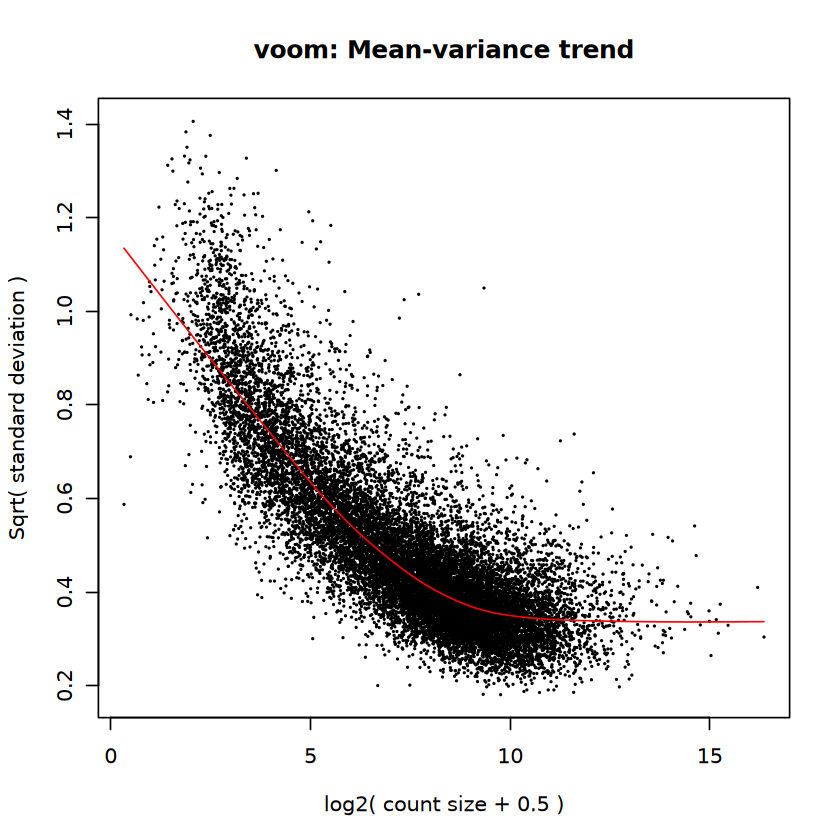

In [17]:
# Loop through each gene in gene_analysis_objects
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # Filter genes by expression
  keep <- filterByExpr(d0, gene_obj$design)
  cat("Genes retained after filtering:", sum(keep), "\n")
  d <- d0[keep, ]
    
  # Obtain log-transformed normalized expression data
  logcpm <- cpm(d, prior.count = 2, log = TRUE)
  write.table(logcpm, 
              paste0("05_gene_counts/", gene_name, "_normalized_counts.txt"),
              sep = "\t", quote = FALSE)
  
  # Clean up design matrix column names
  colnames(gene_obj$design) <- gsub("^Group", "", colnames(gene_obj$design))
  
  # Voom transformation
  y <- voom(d, gene_obj$design, plot = TRUE)
  
  # Fit linear model
  fit <- lmFit(y, gene_obj$design)
  
  # Get all unique groups for this gene
  unique_groups <- unique(gene_obj$metadata$Group)
  cat("Unique groups:", paste(unique_groups, collapse = ", "), "\n")
  cat("Design matrix columns:", paste(colnames(gene_obj$design), collapse = ", "), "\n")
  
  # Generate all possible pairwise comparisons
  if (length(unique_groups) > 1) {
    comparisons <- combn(unique_groups, 2, simplify = FALSE)
  
    # Loop through each pairwise comparison
    for (comparison in comparisons) {
      group1 <- comparison[1]
      group2 <- comparison[2]
      
      cat("  Comparison:", group1, "vs", group2, "\n")
      
      # Define contrast using exact group names
      contr <- makeContrasts(
        contrasts = paste0(group1, "-", group2),
        levels = gene_obj$design
      )
      
      # Estimate contrast for each gene
      tmp <- contrasts.fit(fit, contr)
      
      # Apply eBayes
      tmp <- eBayes(tmp)
      
      # Get results with multiple testing adjustment
      top.table <- topTable(tmp, adjust.method = "BH", sort.by = "P", n = Inf)
      
      # Count significant DEGs
      num_degs <- sum(top.table$adj.P.Val < 0.01)
      cat("    DEGs (adj.P.Val < 0.01):", num_degs, "\n")
      
      # Save results
      write.csv(top.table, 
                file = paste0("05_DEGs/", group1, "_vs_", group2, "_results.csv"),
                row.names = TRUE)
    }
  } else {
    cat("  Only one group found, skipping pairwise comparisons\n")
  }
}